## Домашнее задание 1 (10 баллов)

В рамках этой лабораторной работы вам предстоит освоить на практике этапы первичной обработки информации и ее последующего исследовательского анализа.Вы примените инструменты numpy, pandas, matplotlib и seaborn для решения проблемы, максимально приближенной к рабочим условиям.
Суть задачи — построение модели кредитного скоринга для определения надежности заявителя. Датасет содержит профили 1000 человек, описанных 20 параметрами, с итоговой маркировкой их кредитоспособности. Вам нужно будет привести данные в порядок, проанализировать их (включая создание графиков) и на основе выявленных закономерностей предложить простой метод расчета скорингового балла. Пояснения к полям данных доступны здесь: 

https://www.rdocumentation.org/packages/evtree/versions/1.0-8/topics/GermanCredit

Любая созданная вами диаграмма должна быть аккуратно подписана (название, оси) и сопровождаться небольшим выводом, поясняющим, что на ней показано.

*Функции, которые могут пригодиться при оформлении графиков: `.show()`, `.title()`, `.xlabel()`, `.ylabel()`*

In [ ]:
import pandas as pd
from pathlib import Path

data_dir = Path('./data/')

### Задание 1 (0.0 балла)

Прочитайте средствами pandas файл с данными(файл 'german_credit.csv'). Выведите базовое представление таблицы (первые 5 и последние 5 строк, размер).

In [247]:
data = pd.read_csv(
    filepath_or_buffer=data_dir / 'german_credit.csv'
)

data.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status                   1000 non-null   str  
 1   duration                 1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   amount                   1000 non-null   int64
 5   savings                  1000 non-null   str  
 6   employment_duration      1000 non-null   str  
 7   installment_rate         1000 non-null   str  
 8   personal_status_sex      1000 non-null   str  
 9   other_debtors            1000 non-null   str  
 10  present_residence        1000 non-null   str  
 11  property                 1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  
 15  number_credits  

#### Первые 5 строк

In [3]:
data.head()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,no checking account,18,all credits at this bank paid back duly,car (used),1049,unknown/no savings account,< 1 yr,< 20,female : non-single or male : single,none,...,car or other,21,none,for free,1,skilled employee/official,0 to 2,no,no,good
1,no checking account,9,all credits at this bank paid back duly,others,2799,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,unknown / no property,36,none,for free,2-3,skilled employee/official,3 or more,no,no,good
2,... < 0 DM,12,no credits taken/all credits paid back duly,retraining,841,... < 100 DM,4 <= ... < 7 yrs,25 <= ... < 35,female : non-single or male : single,none,...,unknown / no property,23,none,for free,1,unskilled - resident,0 to 2,no,no,good
3,no checking account,12,all credits at this bank paid back duly,others,2122,unknown/no savings account,1 <= ... < 4 yrs,20 <= ... < 25,male : married/widowed,none,...,unknown / no property,39,none,for free,2-3,unskilled - resident,3 or more,no,yes,good
4,no checking account,12,all credits at this bank paid back duly,others,2171,unknown/no savings account,1 <= ... < 4 yrs,< 20,male : married/widowed,none,...,car or other,38,bank,rent,2-3,unskilled - resident,0 to 2,no,yes,good


#### Последние 5 строк

In [4]:
data.tail()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
995,no checking account,24,no credits taken/all credits paid back duly,furniture/equipment,1987,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,unknown / no property,21,none,for free,1,unskilled - resident,3 or more,no,no,bad
996,no checking account,24,no credits taken/all credits paid back duly,others,2303,unknown/no savings account,>= 7 yrs,< 20,male : married/widowed,co-applicant,...,unknown / no property,45,none,rent,1,skilled employee/official,0 to 2,no,no,bad
997,... >= 200 DM / salary for at least 1 year,21,all credits at this bank paid back duly,others,12680,... >= 1000 DM,>= 7 yrs,< 20,male : married/widowed,none,...,real estate,30,none,own,1,manager/self-empl./highly qualif. employee,0 to 2,yes (under customer name),no,bad
998,... < 0 DM,12,no credits taken/all credits paid back duly,furniture/equipment,6468,... >= 1000 DM,unemployed,25 <= ... < 35,male : married/widowed,none,...,real estate,52,none,rent,1,manager/self-empl./highly qualif. employee,0 to 2,yes (under customer name),no,bad
999,no checking account,30,no credits taken/all credits paid back duly,car (used),6350,... >= 1000 DM,>= 7 yrs,< 20,male : married/widowed,none,...,car or other,31,none,rent,1,skilled employee/official,0 to 2,no,no,bad


#### Размер датасета

In [5]:
data.shape

(1000, 21)

**Вывод:**
- 1000 записей и 21 признак

### Задание 2 (0.5 балла)

Определите, есть ли пропуски в данных. Разделите признаки на количественные, бинарные, порядковые и категориальные.

In [270]:
print(f'Всего пропусков в датасете: {data.isna().sum().sum()}')

nans_count = (
    data.isna()
    .sum()
    .reset_index(name='count_nans')
    .sort_values(by='count_nans', ascending=False)
    .reset_index(drop=True)
    .rename(columns={'index': 'column_name'})
)

display(nans_count)

Всего пропусков в датасете: 0


,column_name,count_nans
0,status,0
1,duration,0
2,credit_history,0
3,amount,0
4,savings,0
5,employment_duration,0
6,installment_rate,0
7,present_residence,0
8,age,0
9,number_credits,0


| # | Признак | Тип |
|---|---------|-----|
| 0 | status | **Категориальный** (порядковый) |
| 1 | duration | **Количественный** |
| 2 | credit_history | **Категориальный** (порядковый) |
| 3 | purpose | **Категориальный** (номинальный) |
| 4 | amount | **Количественный** |
| 5 | savings | **Категориальный** (порядковый) |
| 6 | employment_duration | **Категориальный** (порядковый) |
| 7 | installment_rate | **Категориальный** (порядковый) |
| 8 | personal_status_sex | **Категориальный** (номинальный) |
| 9 | other_debtors | **Категориальный** (номинальный) |
| 10 | present_residence | **Категориальный** (порядковый) |
| 11 | property | **Категориальный** (номинальный) |
| 12 | age | **Количественный** |
| 13 | other_installment_plans | **Категориальный** (номинальный) |
| 14 | housing | **Категориальный** (номинальный) |
| 15 | number_credits | **Категориальный** (порядковый) |
| 16 | job | **Категориальный** (порядковый) |
| 17 | people_liable | **Бинарный** |
| 18 | telephone | **Бинарный** |
| 19 | foreign_worker | **Бинарный** |
| 20 | credit_risk | **Бинарный** |

**Вывод:**
- Явных пропусков (`np.nan`) в датасете нет
- Есть пропуски в виде меток - отсутствие данных: `unknown/no savings account`, `unknown / no property` и `no checking account`.

### Задание 3 (0.5 балла)

Выведите среднюю сумму кредита (колонка amount) в каждой категории (колонка purpose), воспользовавшись методом groupby.

In [ ]:
mean_credit_amount = (
    data.groupby(by='purpose')['amount']
    .mean()
    .reset_index(name='mean_amount')
    .sort_values(by='mean_amount', ascending=False)
    .round(2)
)
display(mean_credit_amount)

,purpose,mean_amount
0,business,8209.33
1,car (new),5370.22
8,retraining,4158.04
7,repairs,3180.40
2,car (used),3066.98
5,others,3062.95
3,domestic appliances,2728.09
4,furniture/equipment,2487.69
6,radio/television,1498.00
9,vacation,1205.89


### Задание 4 (0.5 балла)


Какой процент клиентов моложе 30 лет (колонка age) снимает жилье (колонка housing)? А какой процент клиентов старше 40 лет снимает жилье?

In [ ]:
rent_30 = (data.loc[data['age'] < 30, 'housing'] == 'rent').mean()
print(f'Клиенты моложе 30 лет снимающие жилье: {100 * rent_30:.2f}')

rent_40 = (data.loc[data['age'] > 40, 'housing'] == 'rent').mean()
print(f'Клиенты старше 40 лет снимающие жилье: {100 * rent_40:.2f}')

Клиенты моложе 30 лет снимающие жилье: 66.67
Клиенты старше 40 лет снимающие жилье: 68.01


**Вывод:**
- $66.67\%$ клиентов снимает жилье, которые моложе $30$ лет
- $68.01\%$ клиентов снимает жилье, которые старше $40$ лет

### Задание 5 (0.5 балла)

 У скольких иностранцев (foreign_worker) число кредитов (number_credits) больше 3?

In [260]:
foreign_clients = data.loc[(data['foreign_worker'] == 'yes') & (data.number_credits.isin(['4-5', '>= 6'])), 'age'].count()
print(f'Количество иностранцев у которых больше трех кредитов: {foreign_clients}')

Количество иностранцев у которых больше трех кредитов: 1


**Вывод:**
- Во всей выборке есть $1$ иностранец у которого больше трех кредитов

### Задание 6 (1 балл)

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

my_pallete = sns.color_palette("Set2", 3) 

Используя numpy и matplotlib, начнём с тренировки: постройте график функций $sin(x)$ и $cos(x)$ от $-\pi$ до $\pi$ из 100 точек c легендой и сеткой. Используйте для линий разные цвета, одна из них пусть будет пунктирной. Результат в этом и следующих заданиях на построение графиков должен получиться примерно как на картинке. Содержание подписей не должно обязательно совпадать, однако осмысленные подписи должны присутствовать на графиках.

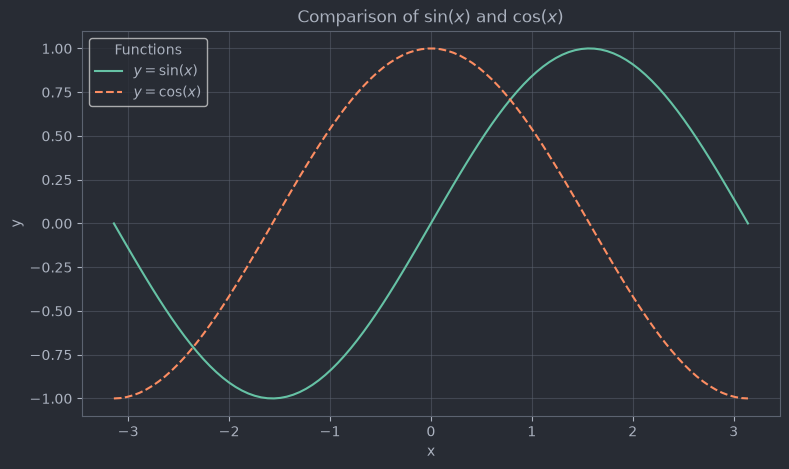

In [271]:
_, ax = plt.subplots(figsize=(9, 5))

x = np.linspace(
    start=-np.pi,
    stop=np.pi,
    num=100
)

ax.plot(x, np.sin(x), label=r'$y=\sin(x)$', color=my_pallete[0], linestyle='-')
ax.plot(x, np.cos(x), label=r'$y=\cos(x)$', color=my_pallete[1], linestyle='--')

ax.set(
    xlabel='x',
    ylabel='y',
    title=r'Comparison of $\sin(x)$ and $\cos(x)$',
)

ax.legend(
    title='Functions',
    loc='upper left'
)
ax.grid(alpha=0.5)

plt.show()

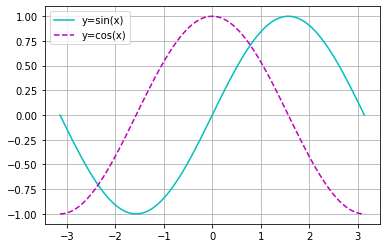

In [8]:
# your code here

### Задание 7 (1 балл)

Рассмотрим сравнительное количество положительных и отрицательных кейсов в зависимости от размера текущего счёта. Постройте зеркальные горизонтальные гистограммы.

In [222]:
good_data = data.loc[data['credit_risk'] == 'good', 'status'].value_counts().to_frame(name='count_good')
bad_data = data.loc[data['credit_risk'] == 'bad', 'status'].value_counts().to_frame(name='count_bad')
status_data = pd.concat([good_data, bad_data], axis=1).sort_index()
status_data

,count_good,count_bad
status,,
... < 0 DM,164,105
... >= 200 DM / salary for at least 1 year,348,46
0<= ... < 200 DM,49,14
no checking account,139,135


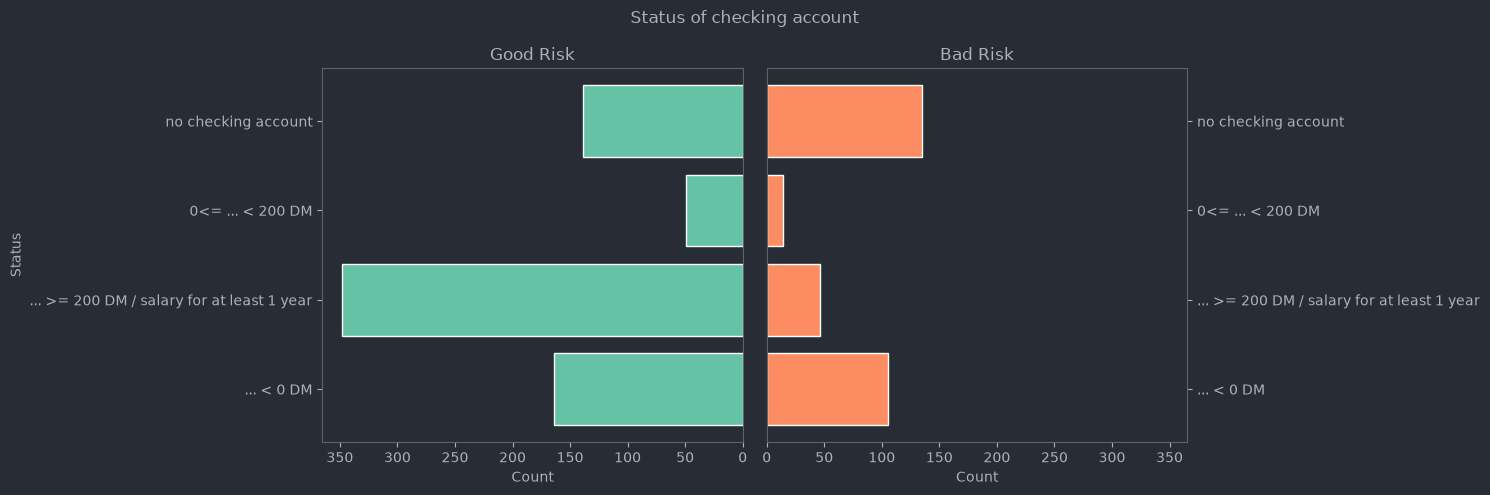

In [262]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, sharey=False, figsize=(15, 5))

ax1.barh(status_data.index.values, status_data.count_good, color=my_pallete[0], edgecolor='w')
ax2.barh(status_data.index.values, status_data.count_bad, color=my_pallete[1], edgecolor='w')

ax1.set(
    xlabel='Count',
    ylabel='Status',
    title='Good Risk'
)
ax1.invert_xaxis()

ax2.set(
    xlabel='Count',
    title='Bad Risk'
)
ax2.yaxis.tick_right()

max_val = max(status_data.count_good.max(), status_data.count_bad.max()) * 1.05
ax1.set_xlim(max_val, 0)
ax2.set_xlim(0, max_val)

fig.subplots_adjust(wspace=0.1)
fig.suptitle(t='Status of checking account')
fig.tight_layout()
plt.show()

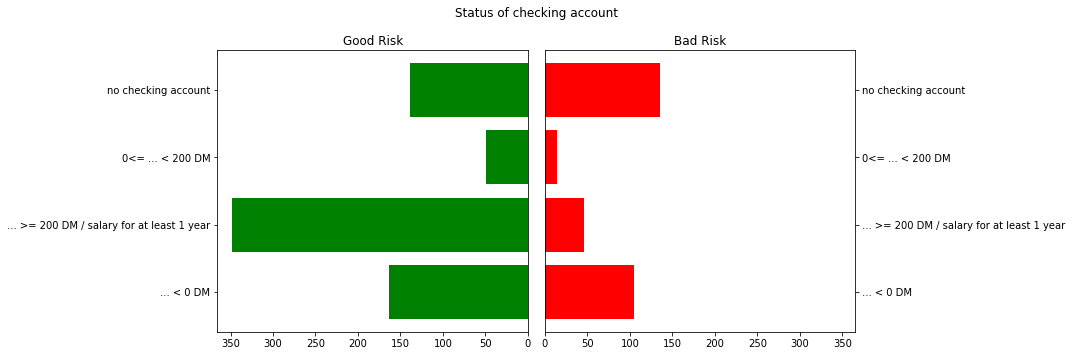

In [9]:
# your code here

### Задание 8  (0.5 балла)

Теперь постройте гистограмму для сравнения количества положительных и отрицательных кейсов в зависимости от размера сберегательного счёта с помощью seaborn. Какой способ вам больше нравится с точки зрения трудоёмкости написания кода? А с точки зрения восприятия результата?

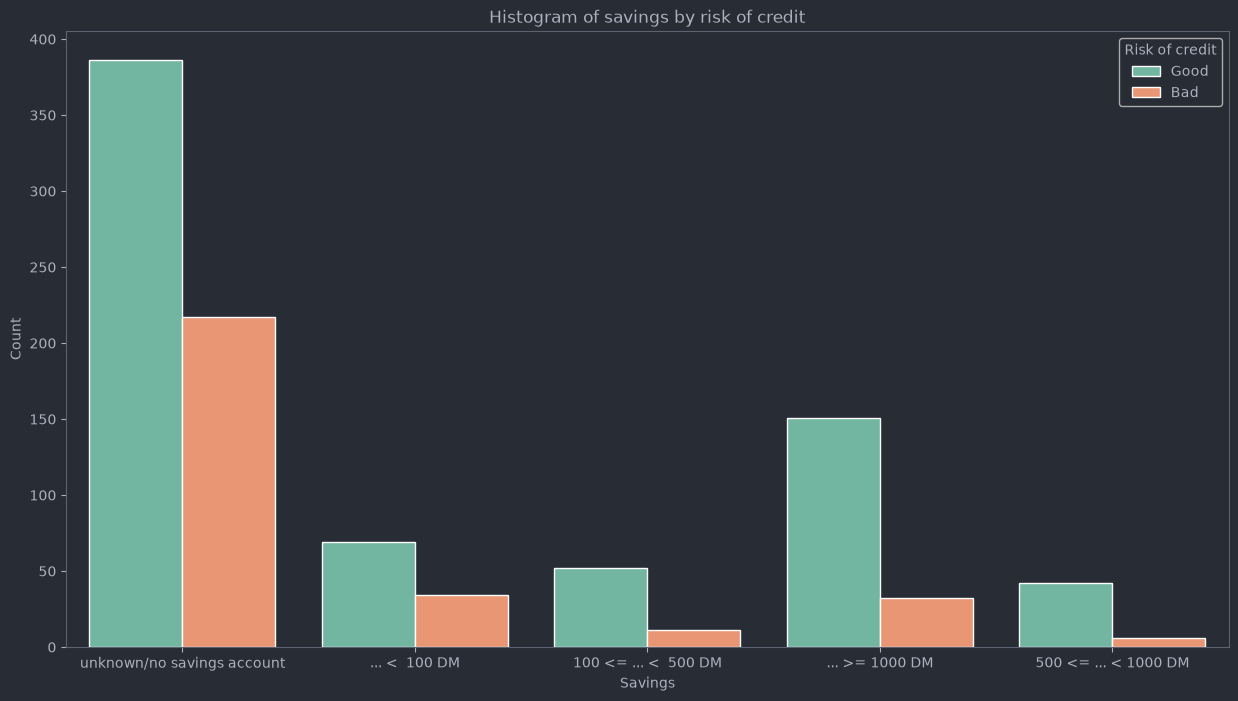

In [221]:
_, ax = plt.subplots(figsize=(15, 8))

sns.countplot(
    data=data,
    x='savings',
    hue='credit_risk', 
    palette=my_pallete[:2], 
    dodge=True, 
    legend=True,
    edgecolor='w',
    ax=ax
)
ax.set(
    title='Histogram of savings by risk of credit',
    xlabel='Savings',
    ylabel='Count'
)

handles, labels = ax.get_legend_handles_labels()
new_labels = [label.capitalize() for label in labels]
ax.legend()
ax.legend(
    handles=handles, 
    labels=new_labels,
    title='Risk of credit', 
)

plt.show()

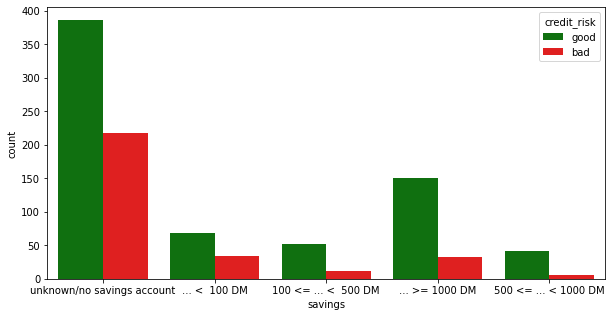

In [11]:
# your code here

### Задание 9  (1 балл)

seaborn легко позволяет добавить ещё больше информации на один график. Для каждого размера сберегательного счёта мы можем оценить не только количество положительных и отрицательных кейсов, но и их распределение по возрасту, например. Постройте подходящую для этого визуализацию.

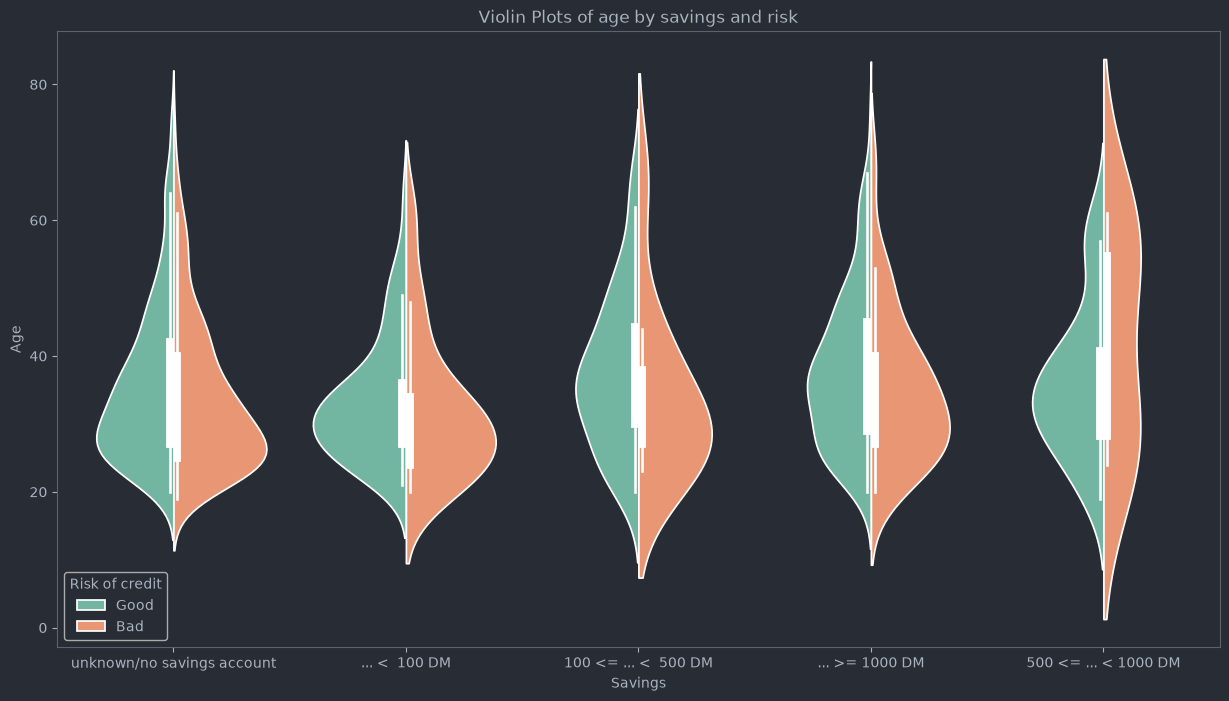

In [220]:
_, ax = plt.subplots(figsize=(15, 8))

sns.violinplot(
    data=data, 
    x='savings', 
    y='age', 
    hue='credit_risk', 
    palette=my_pallete[:2], 
    split=True, 
    edgecolor="w"
)

ax.set(
    title='Violin Plots of age by savings and risk',
    xlabel='Savings',
    ylabel='Age'
)

handles, labels = ax.get_legend_handles_labels()
new_labels = [label.capitalize() for label in labels]
ax.legend()
ax.legend(
    handles=handles, 
    labels=new_labels,
    title='Risk of credit', 
    loc='lower left'
)

plt.show()

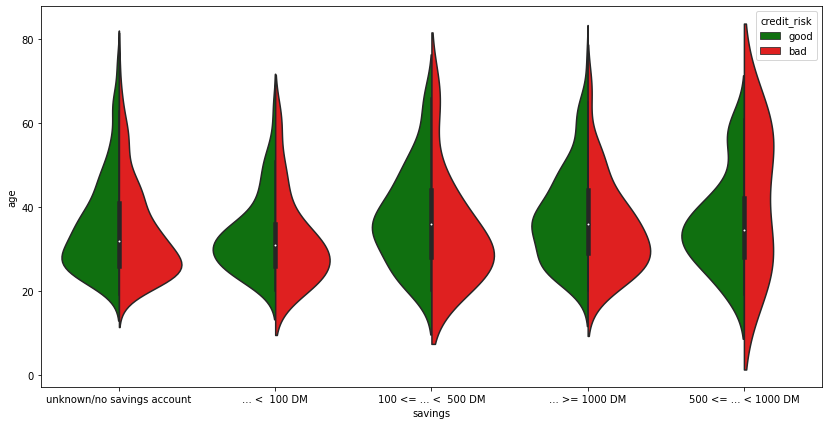

In [12]:
# your code here

### Задание 10  (0.5 балла)

Заканчивая с гистограммами, посмотрим на распределение положительных и отрицательных кейсов по возрастам, разместив их друг над другом. Добавим распределение всех взятых кредитов.

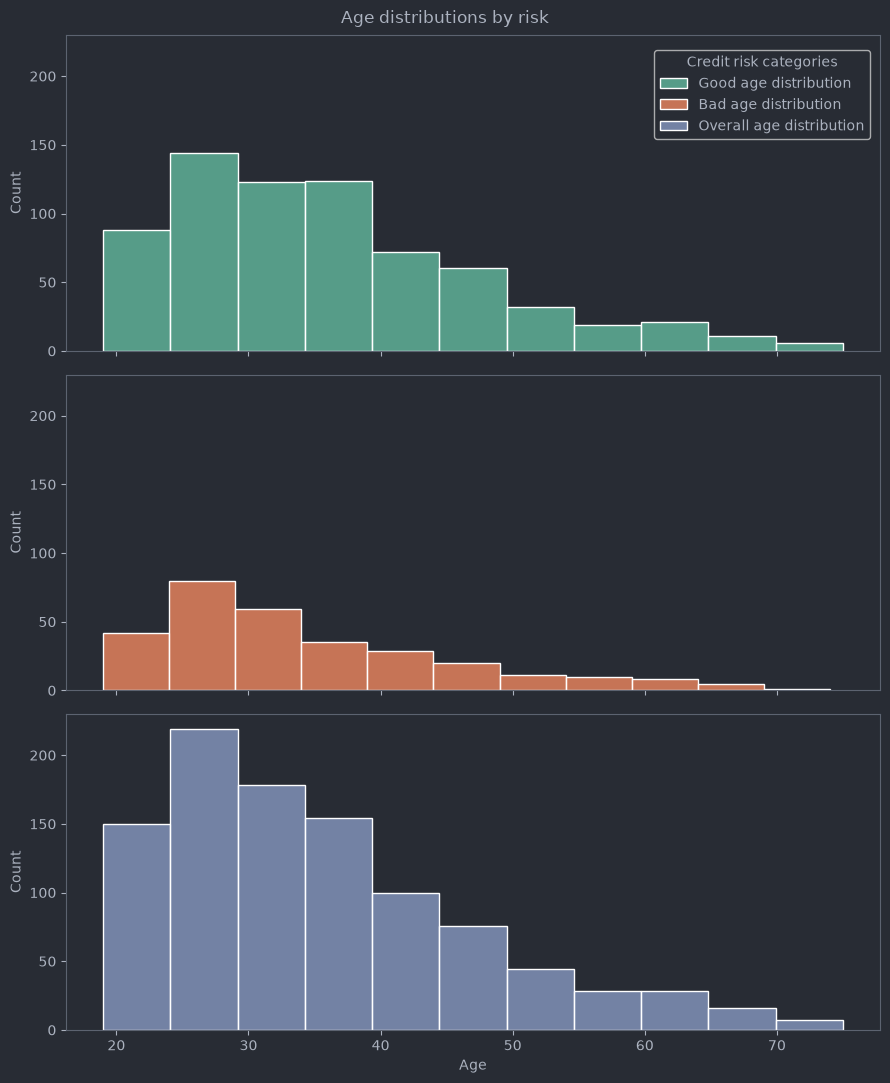

In [261]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 11), sharex=True, sharey=True)

risks = data['credit_risk'].unique().tolist() 
risks.append(risks.copy())
labels = [x + ' age distribution' for x in ['Good', 'Bad', 'Overall']]

for cat, color, ax, label in zip(risks, my_pallete, axes, labels):
    target = cat if isinstance(cat, list) else [cat]
    current_data = data.loc[data['credit_risk'].isin(target)]
    sns.histplot(
        data=current_data,
        x='age',
        color=color,
        label=label,
        bins=11,
        edgecolor='w',
        ax=ax
    )

axes[2].set(
    xlabel='Age'
)

fig.legend(
    title='Credit risk categories',
    bbox_to_anchor=(0.98, 0.95)
)
fig.suptitle(t='Age distributions by risk')
fig.tight_layout()

plt.show()

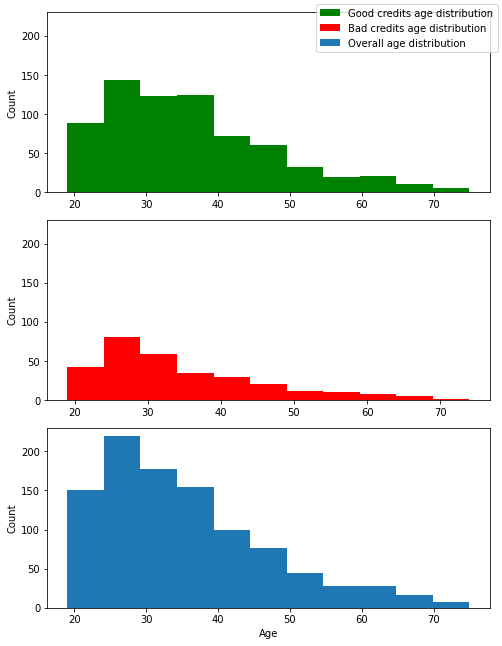

In [13]:
# your code here

### Задание 11  (0.5 балла)

Не менее полезной иногда может быть диаграмма рассеяния. Постройте такую диаграмму с продолжительностью и размерами кредитов в качестве осей. Обозначьте положительные и отрицательные кейсы разными цветами.

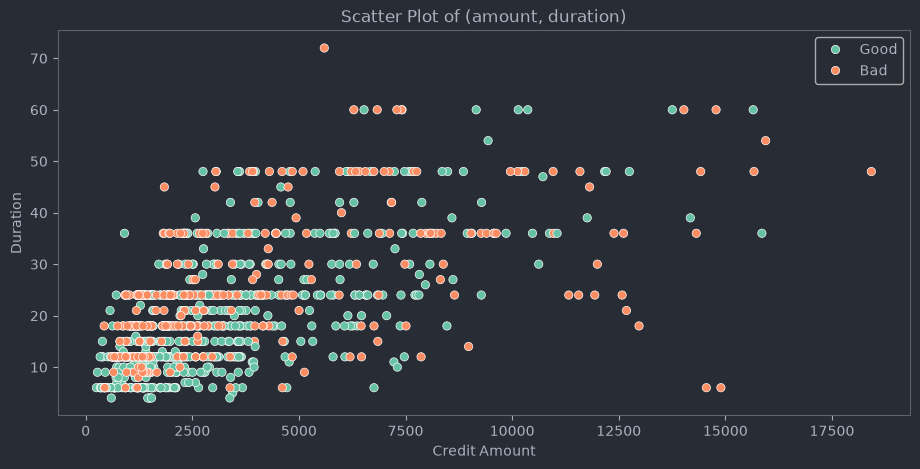

In [219]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.scatterplot(
    data=data,
    x='amount',
    y='duration',
    hue='credit_risk',
    palette=my_pallete[:2]
)

ax.legend(title='Risk of credit')
ax.set(
    title='Scatter Plot of (amount, duration)',
    xlabel='Credit Amount',
    ylabel='Duration'
)

handles, labels = ax.get_legend_handles_labels()
new_labels = [label.capitalize() for label in labels]
ax.legend(handles=handles, labels=new_labels)

plt.show()

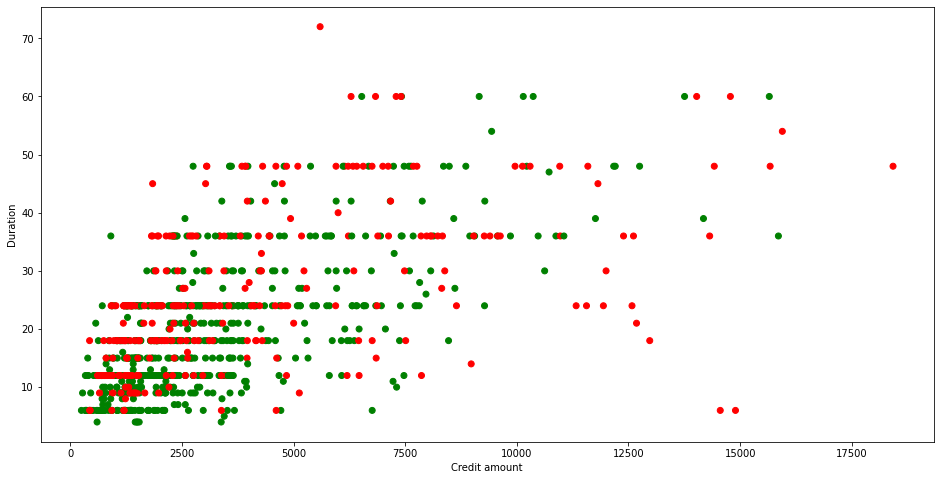

In [21]:
# your code here

### Задание 12  (1 балл)

Продвинемся глубже. Постройте 3D версию диаграммы рассеяния, добавив ось с возрастом.

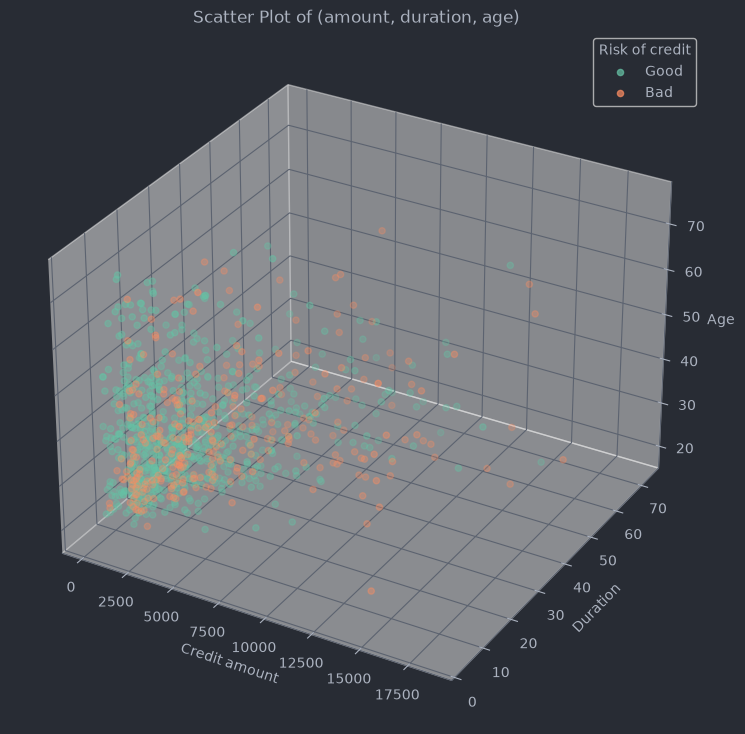

In [ ]:
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(projection='3d')

risks = data['credit_risk'].unique().tolist()
for cat, color in zip(risks, my_pallete[:2]):
    current_data = data.loc[data['credit_risk'] == cat]
    ax.scatter(
        current_data['amount'], 
        current_data['duration'], 
        current_data['age'], 
        color=color, 
        label=cat.capitalize(),
        alpha=0.8
    )

ax.set(
    xlabel='Credit amount',
    ylabel='Duration',
    zlabel='Age',
    title='Scatter Plot of (amount, duration, age)'
)
ax.legend(
    title='Risk of credit'
)

plt.show()

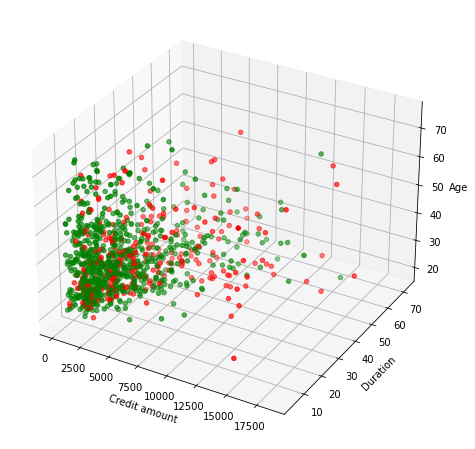

In [15]:
# your code here

### Задание 13  (0.5 балла)

Представьте все порядковые и бинарные признаки в виде числовых значений {0, ..., n - 1}, где n это количество значений признака. Избавьтесь от категориальных признаков.

In [ ]:
binary_columns = [
    'people_liable',
    'telephone',
    'foreign_worker',
    'credit_risk'
]

print('Binary columns:')
for col in binary_columns:
    print(f"'{col}': {data[col].unique().tolist()}")

nominal_columns = [
    'purpose',
    'personal_status_sex',
    'other_debtors',
    'property',
    'other_installment_plans',
    'housing'
]

print('\nNominal columns:')
for col in nominal_columns:
    print(f"'{col}': {data[col].unique().tolist()}")

ordinal_columns = [
    'status',
    'credit_history',
    'savings',
    'employment_duration',
    'installment_rate',
    'present_residence',
    'number_credits',
    'job'
]

print('\nOrdinal columns:')
for col in ordinal_columns:
    print(f"'{col}': {data[col].unique().tolist()}")

Binary columns:
'people_liable': ['0 to 2', '3 or more']
'telephone': ['no', 'yes (under customer name)']
'foreign_worker': ['no', 'yes']
'credit_risk': ['good', 'bad']

Nominal columns:
'purpose': ['car (used)', 'others', 'retraining', 'furniture/equipment', 'car (new)', 'business', 'domestic appliances', 'radio/television', 'repairs', 'vacation']
'personal_status_sex': ['female : non-single or male : single', 'male : married/widowed', 'female : single', 'male : divorced/separated']
'other_debtors': ['none', 'guarantor', 'co-applicant']
'property': ['car or other', 'unknown / no property', 'building soc. savings agr./life insurance', 'real estate']
'other_installment_plans': ['none', 'bank', 'stores']
'housing': ['for free', 'rent', 'own']

Ordinal columns:
'status': ['no checking account', '... < 0 DM', '... >= 200 DM / salary for at least 1 year', '0<= ... < 200 DM']
'credit_history': ['all credits at this bank paid back duly', 'no credits taken/all credits paid back duly', 'existin

In [265]:
orders = {
    'people_liable': ['0 to 2', '3 or more'],
    'telephone': ['no', 'yes (under customer name)'],
    'foreign_worker': ['no', 'yes'],
    'credit_risk': ['bad', 'good'],
    'status': [
        'no checking account', 
        '... < 0 DM', 
        '0<= ... < 200 DM',
        '... >= 200 DM / salary for at least 1 year', 
    ],
    'credit_history': [
        'critical account/other credits elsewhere',
        'delay in paying off in the past',
        'existing credits paid back duly till now',
        'no credits taken/all credits paid back duly',
        'all credits at this bank paid back duly', 
        
    ],
    'savings': [
        'unknown/no savings account', 
        '... <  100 DM', 
        '100 <= ... <  500 DM', 
        '500 <= ... < 1000 DM',
        '... >= 1000 DM'
    ],
    'employment_duration': [
        'unemployed',
        '< 1 yr', 
        '1 <= ... < 4 yrs', 
        '4 <= ... < 7 yrs', 
        '>= 7 yrs'
    ],
    'installment_rate': [
        '< 20',
        '20 <= ... < 25',  
        '25 <= ... < 35', 
        '>= 35'
    ],
    'present_residence': [
        '< 1 yr',
        '1 <= ... < 4 yrs',
        '4 <= ... < 7 yrs', 
        '>= 7 yrs'       
    ],
    'number_credits': [
        '1', 
        '2-3', 
        '4-5', 
        '>= 6'
    ],
    'job': [
        'unemployed/unskilled - non-resident', 
        'unskilled - resident', 
        'skilled employee/official', 
        'manager/self-empl./highly qualif. employee'
    ]
}

In [266]:
for col, val in orders.items():
    data[col] = pd.Categorical(
        values=data[col],
        categories=val,
        ordered=True
    )

In [267]:
data.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   status                   1000 non-null   category
 1   duration                 1000 non-null   int64   
 2   credit_history           1000 non-null   category
 3   purpose                  1000 non-null   category
 4   amount                   1000 non-null   int64   
 5   savings                  1000 non-null   category
 6   employment_duration      1000 non-null   category
 7   installment_rate         1000 non-null   category
 8   personal_status_sex      1000 non-null   category
 9   other_debtors            1000 non-null   category
 10  present_residence        1000 non-null   category
 11  property                 1000 non-null   category
 12  age                      1000 non-null   int64   
 13  other_installment_plans  1000 non-null   category
 14  housing             

In [268]:
original_data = data.copy()

for col in data.select_dtypes(include='category').columns:
    data[col] = data[col].cat.codes

data = data.drop(columns=nominal_columns)
data.head()

,status,duration,credit_history,amount,savings,employment_duration,installment_rate,present_residence,age,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,0,18,4,1049,0,1,0,3,21,0,2,0,0,0,1
1,0,9,4,2799,0,2,2,1,36,1,2,1,0,0,1
2,1,12,3,841,1,3,2,3,23,0,1,0,0,0,1
3,0,12,4,2122,0,2,1,1,39,1,1,1,0,1,1
4,0,12,4,2171,0,2,0,3,38,1,1,0,0,1,1


### Задание 14  (2 балла)

По результатам предыдущего задания у вас должна получиться таблица, в которой все признаки так или иначе представлены числовыми значениями. Попробуйте придумать на основе проведённых исследований данных какую-нибудь формулу, связывающую целевую переменную с признаками, не используя готовых инструментов машинного обучения. По желанию вы можете исключить ещё какие-то признаки, или, наоборот, сформировать новые на основе имеющихся. Возможно, вы захотите отмасштабировать большие наборы численных значений некоторых признаков с помощью интервалов. Цель: реализовать функцию, которая будет принимать на вход набор признаков для объекта выборки и возвращать прогноз целевой переменной (0 или 1). Например, вы можете просто сложить все признаки и возращать ноль, если сумма отрицательная, а в противном случае единицу. Но наверняка можно придумать лучше!
Данные уже разделены на набор для обучения, который вы можете использовать как угодно, и тестовый, на котором нужно будет проверить вашу точность. Постарайтесь достичь точности хотя бы 0.6.

In [258]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
def predict(X_test: np.ndarray) -> np.ndarray:
    ...


x = data.drop(columns='credit_risk').values
y = data['credit_risk'].values

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=10)\



In [ ]:
accuracy_score(y_test, predict(X_test))

0.708